<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm" width="340"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="Vector Gateway Interface" width="170"></a>

# How much reported weight is shared?

Two funds can share many identifiers while assigning very different weights to them. We will match the **SCHD** and **SCHV** holdings lists by nonempty CUSIP, sum positive reported weights within each identifier, and examine the smaller weight assigned to every shared identifier. A minimum-weight parameter will separate tiny shared entries from larger ones.

The default replays **eight official Schwab holdings pages captured November 14, 2026** through the real released worker. They are not synthetic. The endpoint provides current holdings, so this recording is an explicit captured example rather than a historical query. This is a data-comparison exercise, not a return forecast, correlation estimate or fund recommendation. [Setup and provenance](README.md).

## Set the minimum shared weight

`MIN_SHARED_PP` is the minimum reported weight required **in each fund** for an identifier to be included in the selected group. Units are percentage points of each fund’s reported assets: 0.10 means at least 0.10% in SCHD and at least 0.10% in SCHV. Range: 0–5 inclusive. At zero, every identifier with positive weights in both funds qualifies.

`DATA_MODE="recorded"` uses the fixed eight pages. `"live"` fetches current pages for the same funds and updates dates and labels. No arbitrary historical date is supported. Edit, restart, and run all; the end experiment changes only the threshold from 0.10 to 0.50.

In [1]:
MIN_SHARED_PP = 0.10  # percentage points of reported assets in EACH fund; 0..5
DATA_MODE = "recorded"  # recorded or live

In [2]:
import haybarn
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import FuncFormatter, NullFormatter

from notebook_support import chart, cleanup, configure, prose, stage_audit, theme

previous, audit, run_at = configure(MIN_SHARED_PP, DATA_MODE)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = False
connection.execute("CREATE TABLE settings AS SELECT ?::DOUBLE AS threshold_pp", [MIN_SHARED_PP])
%sql connection

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-schwab-portable-92o2utkq/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-schwab-portable-92o2utkq/pyproject.toml.

## Connect to the release

The literal `uvx` command installs the remotely tagged worker with pinned numerical, SDK and HTTP dependencies, then runs the small local transport adapter. The adapter uses the release’s existing factories and catalog. Recorded mode verifies SHA-256 hashes and returns saved response text; live mode calls the release’s normal official client. The same released parser audits pagination metadata. No local worker checkout is imported.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'schwab' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with numpy==2.5.4 --with curl-cffi==0.17.0 --from git+https://github.com/Query-farm/vgi-etf-schwab@v0.4.0 python recorded_worker.py');

,Success


## Retrieve the bounded holdings lists

The literal fund filter is pushed into the worker, limiting the scan to two funds. All remote output is materialized before DataFrame capture. We deliberately avoid scanning the product catalog, which would fetch every fund’s facts page. Here `fund_ticker` identifies the fund and `ticker` identifies a holding; CUSIP is the comparison key.

In [4]:
%%sql
CREATE TABLE requested AS SELECT * FROM (VALUES ('SCHD'),('SCHV')) AS t(fund_ticker);
CREATE TABLE holdings AS
SELECT * FROM schwab.holdings WHERE fund_ticker IN ('SCHD','SCHV');
SELECT fund_ticker, count(*) AS returned_rows, min(as_of_date) AS first_date,
       max(as_of_date) AS last_date
FROM holdings GROUP BY fund_ticker ORDER BY fund_ticker;

,fund_ticker,returned_rows,first_date,last_date
0,SCHD,102,2026-11-12,2026-11-12
1,SCHV,568,2026-11-12,2026-11-12


## Require complete pagination before comparing weights

The released worker propagates a first-page transport error, but later-page failures can leave a partial result. Counting returned rows alone would miss that truncation. The adapter therefore records each requested page, its success, advertised total, parsed row count and source date using the **release’s parser**.

The next SQL requires contiguous, unique pages starting at zero, complete advertised row totals, and one date per fund. A failed, empty, inconsistent or missing later page stops this analysis rather than appearing as an absent holding. This checks transport coverage against the page’s own total; it cannot prove that the issuer’s underlying data are complete or error-free.

In [5]:
stage_audit(connection, audit)

In [6]:
%%sql coverage <<
WITH pages AS (
 SELECT fund_ticker, count(*) AS pages_received, count(DISTINCT page) AS distinct_pages,
        min(page) AS first_page, max(page) AS last_page,
        bool_and(ok) AS all_requests_succeeded, sum(parsed_rows) AS parsed_rows,
        min(advertised_total) AS advertised_min, max(advertised_total) AS advertised_max,
        count(advertised_total) AS totals_seen,
        count(DISTINCT source_date) AS page_dates, count(source_date) AS dated_pages
 FROM page_audit GROUP BY fund_ticker
), returned AS (
 SELECT fund_ticker, count(*) AS returned_rows, min(as_of_date) AS source_date,
        count(DISTINCT as_of_date) AS row_dates, count(as_of_date) AS dated_rows
 FROM holdings GROUP BY fund_ticker
)
SELECT r.fund_ticker, p.*, h.* EXCLUDE(fund_ticker),
       coalesce(p.all_requests_succeeded AND p.first_page = 0
         AND p.pages_received = p.distinct_pages AND p.last_page + 1 = p.pages_received
         AND p.totals_seen = p.pages_received AND p.advertised_min = p.advertised_max
         AND p.advertised_min = h.returned_rows AND p.parsed_rows = h.returned_rows
         AND p.page_dates = 1 AND p.dated_pages = p.pages_received
         AND h.row_dates = 1 AND h.dated_rows = h.returned_rows AND h.returned_rows > 0, false) AS complete
FROM requested r LEFT JOIN pages p USING(fund_ticker) LEFT JOIN returned h USING(fund_ticker)
ORDER BY r.fund_ticker;

In [7]:
display(coverage)
assert len(coverage) == 2 and coverage.complete.all(), "Incomplete or inconsistent holdings pagination"
mode_label = "Recorded official pages" if DATA_MODE == "recorded" else "Live official pages"
date_labels = "; ".join(f"{r.fund_ticker}: {r.source_date:%Y-%m-%d}" for r in coverage.itertuples())
prose(
    f"**{mode_label}.** {date_labels}. "
    + (
        "Dates agree. "
        if coverage.source_date.nunique() == 1
        else "The funds have different dates; this comparison spans different snapshots. "
    )
    + f"All {coverage.pages_received.sum():.0f} pages reconcile to their advertised totals. "
    + f"Run started `{run_at}`; calendar source dates are separate from the UTC capture/run clock."
)

,fund_ticker,fund_ticker_1,pages_received,distinct_pages,first_page,last_page,all_requests_succeeded,parsed_rows,advertised_min,advertised_max,totals_seen,page_dates,dated_pages,returned_rows,source_date,row_dates,dated_rows,complete
0,SCHD,SCHD,2,2,0,1,True,102.0,102.0,102.0,2,1,2,102,2026-11-12,1,102,True
1,SCHV,SCHV,6,6,0,5,True,568.0,568.0,568.0,6,1,6,568,2026-11-12,1,568,True


**Recorded official pages.** SCHD: 2026-11-12; SCHV: 2026-11-12. Dates agree. All 8 pages reconcile to their advertised totals. Run started `2026-11-14T07:01:10.397333+00:00`; calendar source dates are separate from the UTC capture/run clock.

## Establish the identified positive-weight universe

Blank CUSIPs are excluded from matching; they are not all treated as one shared cash position. Unknown weights stay unknown. If an identified row has an unknown weight, this calculation stops because an apparent absence could otherwise become a false zero. Zero and negative rows are counted separately.

For the comparison we sum **positive** rows by `(fund_ticker, CUSIP)` within the validated source date. Repeated identifiers therefore contribute their combined positive weight; we do not assert a false row-level primary key. A security absent from a fund’s complete identified positive subset is assigned zero **within this defined subset**. This says nothing about indirect exposures, derivatives, issuer equivalence or identifiers that changed.

In [8]:
%%sql diagnostics <<
SELECT fund_ticker, count(*) AS rows,
       count(*) FILTER (WHERE trim(cusip) = '') AS blank_id_rows,
       count(*) FILTER (WHERE weight_percent IS NULL) AS unknown_weight_rows,
       count(*) FILTER (WHERE trim(cusip) <> '' AND weight_percent IS NULL) AS unknown_identified_rows,
       count(*) FILTER (WHERE weight_percent = 0) AS zero_rows,
       count(*) FILTER (WHERE weight_percent < 0) AS negative_rows,
       sum(weight_percent) AS known_net_percent,
       sum(weight_percent) FILTER (WHERE trim(cusip) = '' AND weight_percent > 0) AS unidentified_positive_percent,
       sum(weight_percent) FILTER (WHERE trim(cusip) <> '' AND weight_percent > 0) AS identified_positive_percent
FROM holdings GROUP BY fund_ticker ORDER BY fund_ticker;

In [9]:
display(diagnostics)
assert diagnostics.unknown_identified_rows.eq(0).all(), "Unknown identified weights prevent the comparison"
assert diagnostics.identified_positive_percent.gt(0).all(), "Missing positive identified-weight denominator"
prose(
    "All following overlap figures use known positive weights with nonempty CUSIPs. "
    "We retain the provider's reported percentage-point scale rather than rescaling either list to 100. "
    "Displayed market values are abbreviated by the website and are not used to reconstruct weights."
)

,fund_ticker,rows,blank_id_rows,unknown_weight_rows,unknown_identified_rows,zero_rows,negative_rows,known_net_percent,unidentified_positive_percent,identified_positive_percent
0,SCHD,102,0,0,0,2,0,100.02,NaN,100.02
1,SCHV,568,0,0,0,5,0,100.04,NaN,100.04


All following overlap figures use known positive weights with nonempty CUSIPs. We retain the provider's reported percentage-point scale rather than rescaling either list to 100. Displayed market values are abbreviated by the website and are not used to reconstruct weights.

## Join identifiers and compute the smaller weight

For each identifier in the union, let \(a_i\) and \(b_i\) be its positive reported weights in SCHD and SCHV. Its common weight contribution is \(m_i=\min(a_i,b_i)\). We report \(\sum_i m_i\), in percentage points, without claiming it represents an actual combined portfolio.

An independent algebraic form verifies the calculation:

\[
\sum_i \min(a_i,b_i)=\frac{\sum_i a_i+\sum_i b_i-\sum_i |a_i-b_i|}{2}.
\]

An identifier passes the selected cutoff when it has positive weight in both lists and \(m_i\geq\text{MIN\_SHARED\_PP}\). The selected sum is a subset of the full common-weight sum. A threshold can change that selected summary without changing the underlying overlap.

In [10]:
%%sql
CREATE TABLE security_weights AS
SELECT fund_ticker, trim(cusip) AS cusip, min(name) AS name,
       sum(weight_percent) AS weight_pp, count(*) AS source_rows
FROM holdings WHERE trim(cusip) <> '' AND weight_percent > 0
GROUP BY fund_ticker, trim(cusip);
CREATE TABLE joined AS
SELECT coalesce(a.cusip,b.cusip) AS cusip, coalesce(a.name,b.name) AS name,
       coalesce(a.weight_pp,0) AS schd_pp, coalesce(b.weight_pp,0) AS schv_pp,
       least(coalesce(a.weight_pp,0),coalesce(b.weight_pp,0)) AS common_pp,
       a.cusip IS NOT NULL AND b.cusip IS NOT NULL AS shared
FROM (SELECT * FROM security_weights WHERE fund_ticker='SCHD') a
FULL OUTER JOIN (SELECT * FROM security_weights WHERE fund_ticker='SCHV') b USING(cusip);
CREATE TABLE summary AS
SELECT count(*) AS union_ids, count(*) FILTER (WHERE shared) AS shared_ids,
       sum(schd_pp) AS schd_total_pp, sum(schv_pp) AS schv_total_pp,
       sum(common_pp) AS full_common_pp,
       count(*) FILTER (WHERE shared AND common_pp >= p.threshold_pp) AS selected_ids,
       coalesce(sum(common_pp) FILTER (WHERE shared AND common_pp >= p.threshold_pp),0) AS selected_common_pp,
       (sum(schd_pp)+sum(schv_pp)-sum(abs(schd_pp-schv_pp)))/2 AS common_via_l1_pp
FROM joined CROSS JOIN settings p;
SELECT * FROM summary;

,union_ids,shared_ids,schd_total_pp,schv_total_pp,full_common_pp,selected_ids,selected_common_pp,common_via_l1_pp
0,608,55,100.02,100.04,17.41,33,16.34,17.41


In [11]:
%%sql
SELECT cusip, name, schd_pp, schv_pp, common_pp,
       common_pp >= (SELECT threshold_pp FROM settings) AS meets_cutoff
FROM joined WHERE shared ORDER BY common_pp DESC, cusip LIMIT 12;

,cusip,name,schd_pp,schv_pp,common_pp,meets_cutoff
0,166764100,CHEVRON,3.96,1.40,1.40,True
1,742718109,PROCTER & GAMBLE,4.41,1.28,1.28,True
2,191216100,COCA-COLA,4.28,1.24,1.24,True
3,58933Y105,MERCK & CO INC,3.76,1.19,1.19,True
4,437076102,HOME DEPOT,4.24,1.14,1.14,True
5,882508104,TEXAS INSTRUMENT,4.76,0.93,0.93,True
6,031162100,AMGEN INC,4.09,0.83,0.83,True
7,713448108,PEPSICO,3.93,0.64,0.64,True
8,92343V104,VERIZON COMMUNICATIONS INC,3.60,0.63,0.63,True
9,747525103,QUALCOMM,4.04,0.62,0.62,True


## Compute the entire threshold response

The curve evaluates every observed common weight, zero, the selected cutoff, and a point just above the largest contribution. Each threshold includes equality. As the requirement increases, both the qualifying identifier count and selected common-weight sum can only decrease. These are conditional summaries of the same saved lists, not fresh requests.

In [12]:
%%sql
CREATE TABLE thresholds AS
SELECT 0.0::DOUBLE AS cutoff_pp
UNION SELECT common_pp FROM joined WHERE shared
UNION SELECT threshold_pp FROM settings
UNION SELECT coalesce(max(common_pp),0) + 0.01 FROM joined;
CREATE TABLE threshold_curve AS
SELECT t.cutoff_pp, count(j.cusip) AS ids,
       coalesce(sum(j.common_pp),0) AS common_pp
FROM thresholds t LEFT JOIN joined j ON j.shared AND j.common_pp >= t.cutoff_pp
GROUP BY t.cutoff_pp;
SELECT * FROM threshold_curve WHERE cutoff_pp = (SELECT threshold_pp FROM settings);

,cutoff_pp,ids,common_pp
0,0.1,33,16.34


In [13]:
%%sql checks <<
SELECT 'known reported weights are finite' AS invariant,
       (SELECT bool_and(NOT isnan(weight_percent) AND NOT isinf(weight_percent)) FROM holdings WHERE weight_percent IS NOT NULL) AS passed
UNION ALL SELECT 'fund and CUSIP pairs are unique after grouping',
       (SELECT count(*) = count(DISTINCT (fund_ticker,cusip)) FROM security_weights)
UNION ALL SELECT 'joined identifiers are unique', (SELECT count(*)=count(DISTINCT cusip) FROM joined)
UNION ALL SELECT 'grouping preserves identified positive weight',
       (SELECT abs(sum(weight_pp)-(SELECT sum(weight_percent) FROM holdings WHERE trim(cusip)<>'' AND weight_percent>0)) < 1e-8 FROM security_weights)
UNION ALL SELECT 'common weight is bounded by each list total',
       (SELECT full_common_pp >= 0 AND full_common_pp <= least(schd_total_pp,schv_total_pp)+1e-8 FROM summary)
UNION ALL SELECT 'minimum and absolute-difference forms agree',
       (SELECT abs(full_common_pp-common_via_l1_pp) < 1e-8 FROM summary)
UNION ALL SELECT 'only positive weights in both lists are shared',
       (SELECT bool_and(shared = (schd_pp>0 AND schv_pp>0)) FROM joined)
UNION ALL SELECT 'selected count and weight are subsets',
       (SELECT selected_ids <= shared_ids AND selected_common_pp BETWEEN 0 AND full_common_pp+1e-8 FROM summary)
UNION ALL SELECT 'selected curve point agrees with selected summary',
       (SELECT s.selected_ids=c.ids AND abs(s.selected_common_pp-c.common_pp)<1e-8 FROM summary s CROSS JOIN threshold_curve c CROSS JOIN settings p WHERE c.cutoff_pp=p.threshold_pp)
UNION ALL SELECT 'both threshold responses are nonincreasing',
       (SELECT bool_and(ids<=prior_ids AND common_pp<=prior_weight+1e-8)
        FROM (SELECT *,lag(ids,1,ids) OVER(ORDER BY cutoff_pp) AS prior_ids,
              lag(common_pp,1,common_pp) OVER(ORDER BY cutoff_pp) AS prior_weight FROM threshold_curve));

In [14]:
display(checks)
assert checks.passed.fillna(False).all(), "An overlap invariant failed"
s = connection.execute("SELECT * FROM summary").df().iloc[0]
pairs = connection.execute("SELECT * FROM joined WHERE shared ORDER BY common_pp DESC,cusip").df()
curve = connection.execute("SELECT * FROM threshold_curve ORDER BY cutoff_pp").df()
prose(
    f"The lists share **{s.shared_ids:.0f} CUSIPs** with positive weights in both. "
    f"Their full common-weight sum is **{s.full_common_pp:.2f} percentage points**. "
    f"At the **{MIN_SHARED_PP:.2f}-point** requirement in each fund, "
    f"**{s.selected_ids:.0f} identifiers** qualify, contributing **{s.selected_common_pp:.2f} points**. "
    f"The other shared identifiers account for {s.full_common_pp - s.selected_common_pp:.2f} points. "
    "No weight is inferred for blank identifiers or unavailable observations."
)

,invariant,passed
0,known reported weights are finite,True
1,fund and CUSIP pairs are unique after grouping,True
2,joined identifiers are unique,True
3,grouping preserves identified positive weight,True
4,common weight is bounded by each list total,True
5,minimum and absolute-difference forms agree,True
6,only positive weights in both lists are shared,True
7,selected count and weight are subsets,True
8,selected curve point agrees with selected summary,True
9,both threshold responses are nonincreasing,True


The lists share **55 CUSIPs** with positive weights in both. Their full common-weight sum is **17.41 percentage points**. At the **0.10-point** requirement in each fund, **33 identifiers** qualify, contributing **16.34 points**. The other shared identifiers account for 1.07 points. No weight is inferred for blank identifiers or unavailable observations.

## Compare the two weights directly

Every point is a CUSIP with positive weight in both funds. The axes share a logarithmic scale so small entries remain visible; equal position on the diagonal means equal reported weight. Amber points meet the selected threshold in both funds. The dashed horizontal and vertical lines show the cutoff when it is positive. Labels identify the largest common-weight contributions, not a recommendation.

findfont: Failed to find font weight semibold for Arial, now using 700.


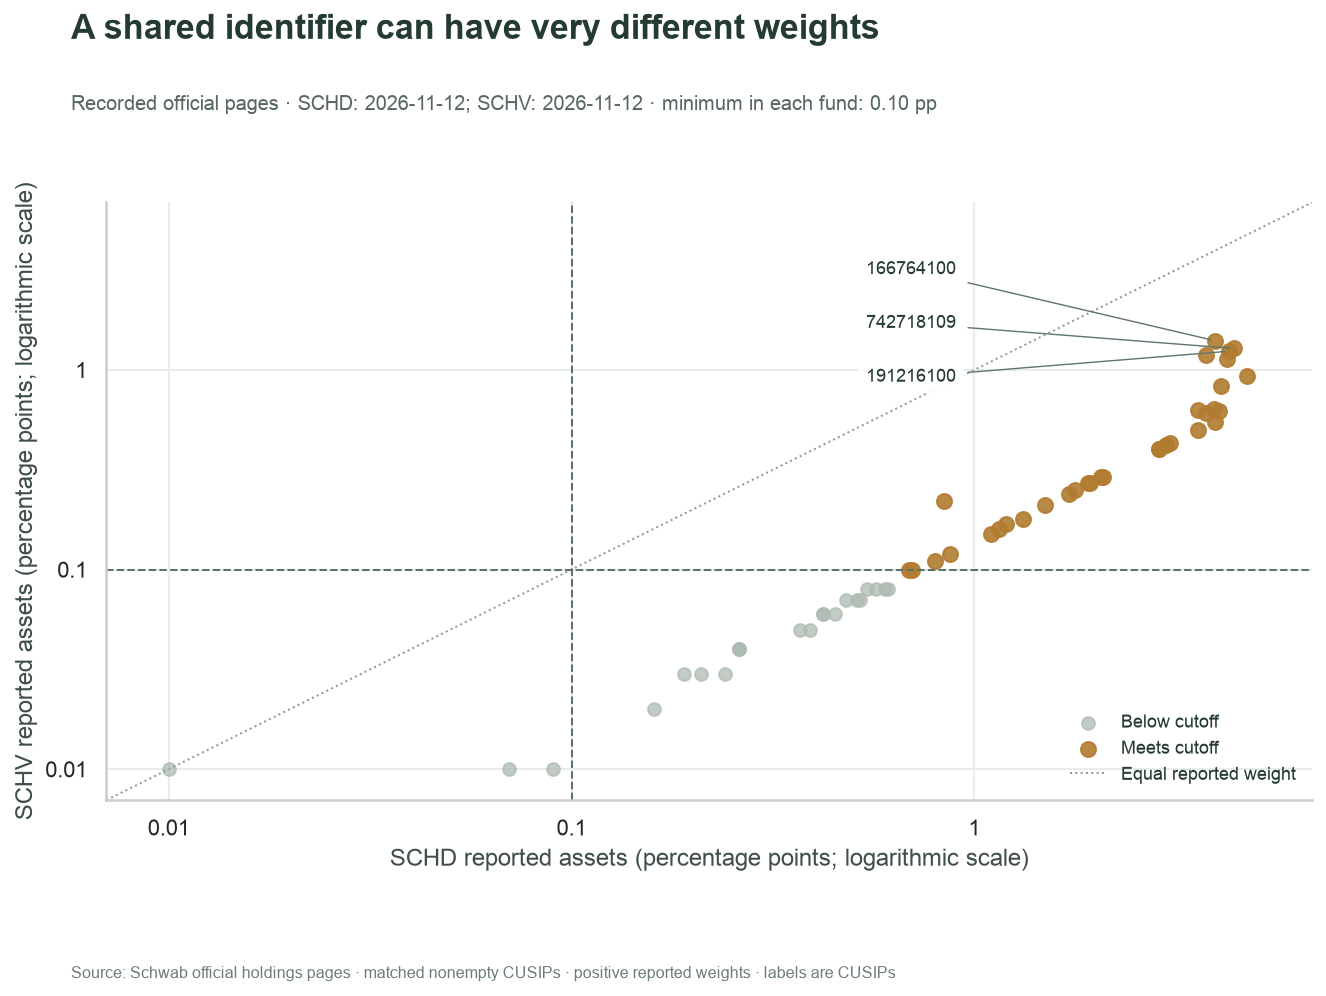

In [15]:
fig, ax = plt.subplots(figsize=(9.5, 7))
if len(pairs):
    selected = pairs.common_pp >= MIN_SHARED_PP
    ax.scatter(
        pairs.schd_pp[~selected],
        pairs.schv_pp[~selected],
        s=40,
        color="#AEBBB2",
        label="Below cutoff",
        alpha=0.75,
    )
    ax.scatter(
        pairs.schd_pp[selected],
        pairs.schv_pp[selected],
        s=55,
        color="#B17C31",
        label="Meets cutoff",
        alpha=0.9,
    )
    low = min(pairs.schd_pp.min(), pairs.schv_pp.min()) * 0.7
    high = max(pairs.schd_pp.max(), pairs.schv_pp.max(), MIN_SHARED_PP) * 1.45
    ax.plot(
        [low, high], [low, high], color="#8E9D93", linewidth=1, linestyle=":", label="Equal reported weight"
    )
    if MIN_SHARED_PP > 0:
        ax.axvline(MIN_SHARED_PP, color="#5B7466", linestyle="--", linewidth=1)
        ax.axhline(MIN_SHARED_PP, color="#5B7466", linestyle="--", linewidth=1)
    for i, row in enumerate(pairs.head(3).itertuples()):
        ax.annotate(
            row.cusip,
            (row.schd_pp, row.schv_pp),
            xytext=(0.63, 0.88 - 0.09 * i),
            textcoords="axes fraction",
            fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
            arrowprops={"arrowstyle": "-", "color": "#60766A", "linewidth": 0.7},
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
        axis.set_minor_formatter(NullFormatter())
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
else:
    ax.text(0.5, 0.5, "No positive-weight CUSIPs are shared", transform=ax.transAxes, ha="center")
ax.set_xlabel("SCHD reported assets (percentage points; logarithmic scale)")
ax.set_ylabel("SCHV reported assets (percentage points; logarithmic scale)")
ax.legend(loc="lower right", fontsize=9)
chart(
    fig,
    "A shared identifier can have very different weights",
    f"{mode_label} · {date_labels} · minimum in each fund: {MIN_SHARED_PP:.2f} pp",
    "Source: Schwab official holdings pages · matched nonempty CUSIPs · "
    "positive reported weights · labels are CUSIPs",
)

## Separate the threshold’s effect on count and weight

The same threshold can remove many small entries while retaining most common weight. The upper panel counts qualifying identifiers; the lower panel sums their smaller reported weights. The step convention includes the point at equality, consistent with the SQL `>=` filter.

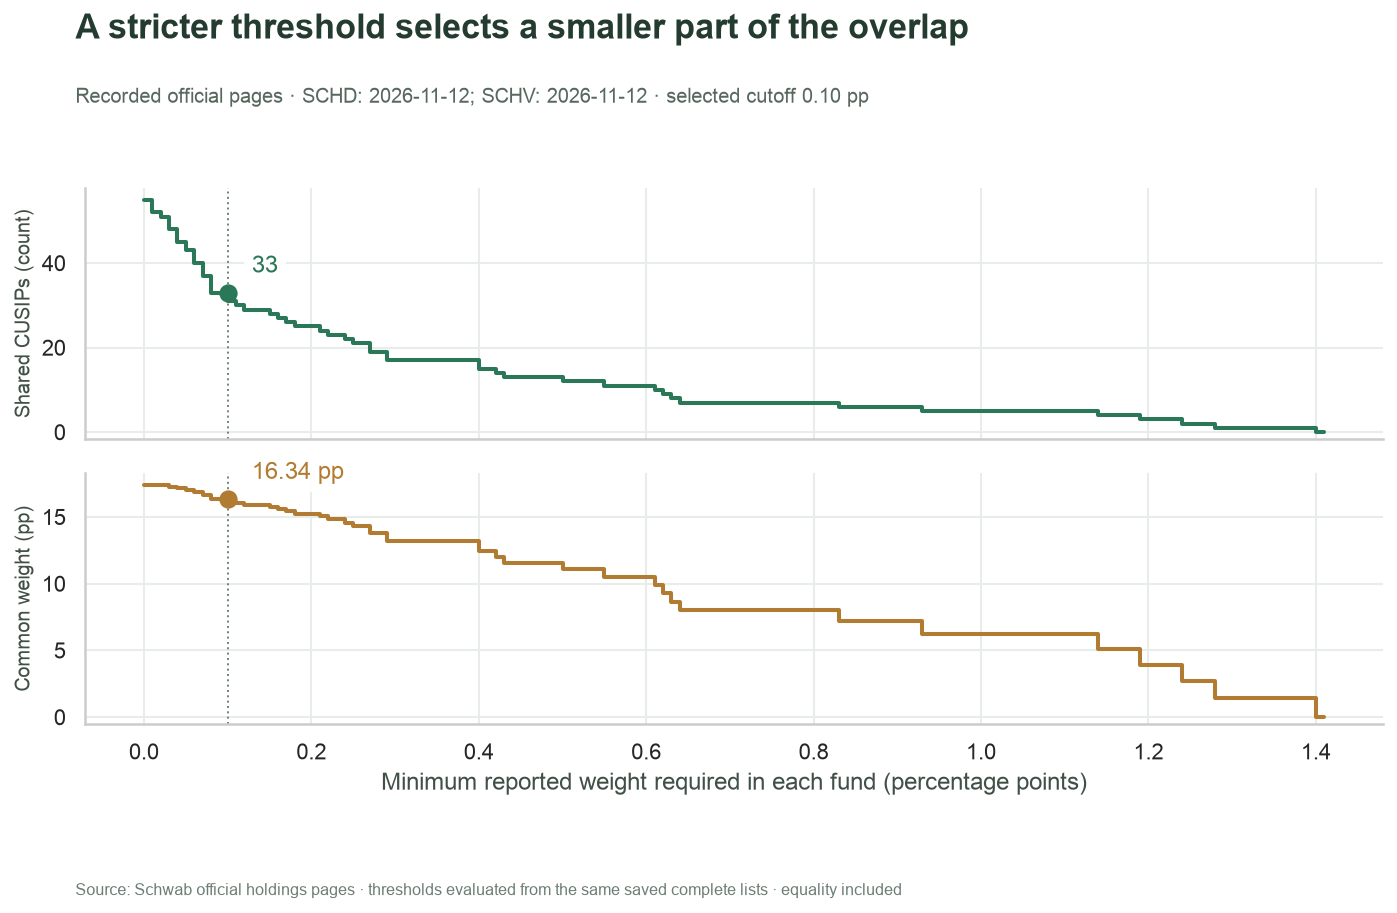

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
for ax, column, label, color in [
    (axes[0], "ids", "Shared CUSIPs (count)", "#2A7857"),
    (axes[1], "common_pp", "Common weight (pp)", "#B17C31"),
]:
    ax.step(curve.cutoff_pp, curve[column], where="pre", color=color, linewidth=2)
    row = curve[curve.cutoff_pp.eq(MIN_SHARED_PP)].iloc[0]
    ax.scatter([MIN_SHARED_PP], [row[column]], color=color, s=65, zorder=4)
    ax.axvline(MIN_SHARED_PP, color="#75877C", linewidth=1, linestyle=":")
    ax.set_ylabel(label, fontsize=10)
    ax.set_ylim(bottom=-0.03 * max(1, curve[column].max()))
    ax.annotate(
        f"{row[column]:.0f}" if column == "ids" else f"{row[column]:.2f} pp",
        (MIN_SHARED_PP, row[column]),
        xytext=(12, 10),
        textcoords="offset points",
        color=color,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
    )
axes[1].set_xlabel("Minimum reported weight required in each fund (percentage points)")
chart(
    fig,
    "A stricter threshold selects a smaller part of the overlap",
    f"{mode_label} · {date_labels} · selected cutoff {MIN_SHARED_PP:.2f} pp",
    "Source: Schwab official holdings pages · thresholds evaluated from the same saved complete lists · "
    "equality included",
)

## Experiment: require half a percentage point in each fund

Change **`MIN_SHARED_PP` from 0.10 to 0.50**, restart and run all. Predict that neither the selected count nor selected common weight can increase: the rule has become stricter. Compare the amber scatter points and highlighted curve positions. The original rows, CUSIP aggregates, source dates and full common-weight sum must stay fixed in recorded mode. Reset `MIN_SHARED_PP = 0.10` afterward. The README provides a separate-output command.

The cutoff is an analytical choice, not an industry materiality standard. A shared CUSIP does not establish equal issuer exposure, correlated returns or portfolio suitability. Positive-weight-only matching also omits negative positions and identifiers unavailable in the source. Changing to live mode introduces a time comparison and is separate from this one-parameter experiment.

In [17]:
connection.close()
cleanup(previous)
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm" width="340"></a>